# BridgeRNA gene-biology benchmark

This report adapts the fixed splits from Zhong et al. (2025) to the frozen BridgeRNA model. It compares the static token embedding (E0), the layer-12 representation under a null input (E1), and the layer-12 representation averaged over a frozen 200-sample GTEx panel (E2). A static-only extension evaluates the locally available BulkFormer-50M and BulkFormer-147M embedding tables on GO and OMIM. All values below are loaded from pipeline outputs; the notebook does not recompute embeddings or probes.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

BENCH = Path.cwd()
if BENCH.name != "zhong_gene_biology":
    BENCH = Path("benchmarks/zhong_gene_biology")
RESULTS = BENCH / "results"
COVERAGE = BENCH / 'coverage'

## Cohort, mapping, and representations

BridgeRNA is evaluated in its canonical 15,165-token order. Human Entrez mappings are retained only when unambiguous and one-to-one. E2 uses a fixed 200-sample GTEx manifest and natural `log1p(TPM)` input; the backbone remains frozen.

In [2]:
coverage = pd.read_csv(COVERAGE / "coverage_summary.csv")
display(coverage)
with (COVERAGE / "representation_qc_e0_e1_e2.json").open() as handle:
    representation_qc = json.load(handle)
representation_qc

,section,metric,value
0,overall,bridge_total_genes,15165.000000
1,overall,bridge_mapped_rows,15150.000000
2,overall,bridge_mapped_unique_entrez,15150.000000
3,overall,bridge_unmapped_rows,11.000000
4,overall,bridge_ambiguous_rows,4.000000
5,overall,bridge_duplicate_entrez_rows,0.000000
6,overall,benchmark_genes_single_gene_tasks,15092.000000
7,overall,benchmark_genes_pair_tasks,10294.000000
8,overall,benchmark_genes_union,16968.000000
9,overall,overlapping_genes,13913.000000


{'status': 'complete',
 'elapsed_seconds': 37.41732311248779,
 'representation_shapes': {'E0': [15165, 512],
  'E1': [15165, 512],
  'E2': [15165, 512]},
 'finite_checks': {'E0': True, 'E1': True, 'E2': True},
 'sample_processing': {'target_samples': 200,
  'processed_samples': 200,
  'silently_dropped_samples': 0,
  'all_target_samples_processed': True},
 'cosine_distributions': {'E0_vs_E1': {'min': -0.05054545775055885,
   'p25': 0.09400797635316849,
   'median': 0.12442506104707718,
   'mean': 0.12378719449043274,
   'p75': 0.153798446059227,
   'max': 0.3025044798851013},
  'E0_vs_E2': {'min': -0.00930811744183302,
   'p25': 0.15478874742984772,
   'median': 0.1879337877035141,
   'mean': 0.1884179264307022,
   'p75': 0.2229146659374237,
   'max': 0.38104456663131714},
  'E1_vs_E2': {'min': 0.20323900878429413,
   'p25': 0.7483037114143372,
   'median': 0.8056433200836182,
   'mean': 0.7842403054237366,
   'p75': 0.8405908346176147,
   'max': 0.9145885705947876}},
 'pairwise_geomet

## Single-gene GO and OMIM prediction

RBF SVM hyperparameters are chosen only from the supplied training folds, then evaluated once on the supplied holdout. Terms that lose either class after mapping are excluded explicitly.

In [3]:
single = pd.read_csv(RESULTS / "representation_summary.csv")
display(single.round(3))
display(pd.read_csv(RESULTS / "comparison_summary_AUROC.csv").round(3))
display(pd.read_csv(RESULTS / "comparison_summary_AUPRC.csv").round(3))

,task,representation,N_terms,median_AUROC,IQR_AUROC,median_AUPRC,median_Precision@10
0,GO,E0_static,56,0.516,0.072,0.117,0.1
1,GO,E1_null_L12,56,0.774,0.096,0.335,0.4
2,GO,E2_GTEx200_L12,56,0.788,0.108,0.378,0.5
3,OMIM,E0_static,103,0.495,0.139,0.111,0.1
4,OMIM,E1_null_L12,103,0.744,0.206,0.325,0.3
5,OMIM,E2_GTEx200_L12,103,0.754,0.198,0.400,0.3


,task,comparison,n_terms,median_delta,mean_delta,iqr_delta,median_delta_ci_low,median_delta_ci_high,fraction_positive_delta,wilcoxon_stat,wilcoxon_p
0,GO,E1-E0,56,0.241,0.254,0.120,0.218,0.277,1.000,0.0,0.000
1,GO,E2-E1,56,0.011,0.009,0.032,0.000,0.016,0.643,534.0,0.031
2,GO,E2-E0,56,0.256,0.263,0.100,0.232,0.281,0.982,1.0,0.000
3,OMIM,E1-E0,103,0.228,0.246,0.224,0.194,0.284,0.932,129.0,0.000
4,OMIM,E2-E1,103,0.011,0.024,0.082,0.000,0.025,0.583,1696.5,0.004
5,OMIM,E2-E0,103,0.251,0.271,0.217,0.208,0.314,0.951,35.0,0.000


,task,comparison,n_terms,median_delta,mean_delta,iqr_delta,median_delta_ci_low,median_delta_ci_high,fraction_positive_delta,wilcoxon_stat,wilcoxon_p
0,GO,E1-E0,56,0.217,0.235,0.148,0.186,0.244,1.000,0.0,0.0
1,GO,E2-E1,56,0.029,0.035,0.059,0.011,0.042,0.732,307.0,0.0
2,GO,E2-E0,56,0.259,0.270,0.175,0.219,0.292,1.000,0.0,0.0
3,OMIM,E1-E0,103,0.174,0.227,0.301,0.145,0.217,0.922,232.0,0.0
4,OMIM,E2-E1,103,0.035,0.042,0.105,0.017,0.051,0.680,1359.0,0.0
5,OMIM,E2-E0,103,0.261,0.269,0.353,0.153,0.341,0.942,155.0,0.0


### Zhong-matched aggregation across terms

Zhong et al. report **mean AUROC across biological terms** for their headline single-gene comparison. The table below therefore uses the unweighted arithmetic mean of the final held-out AUROC for 56 GO Biological Process terms or 103 OMIM terms. Each term contributes exactly one value. The median is retained as a distribution-robust reference, and sample SD (`ddof=1`) describes between-term variation. CV-fold scores, individual predictions, and gene-count-weighted or pooled metrics are not included in this aggregation.

In [4]:
zhong_matched = pd.read_csv(RESULTS / "single_gene_zhong_matched_summary.csv")
display(zhong_matched[[
    "Task", "Representation", "N_terms", "Mean_AUROC", "Median_AUROC", "SD_AUROC",
    "Mean_AUPRC", "Median_AUPRC", "SD_AUPRC"
]].round(4))

,Task,Representation,N_terms,Mean_AUROC,Median_AUROC,SD_AUROC,Mean_AUPRC,Median_AUPRC,SD_AUPRC
0,GO,E0,56,0.5177,0.5156,0.0681,0.1321,0.1173,0.0627
1,GO,E1,56,0.7722,0.7736,0.0744,0.3668,0.3347,0.1288
2,GO,E2,56,0.7811,0.7876,0.0782,0.4019,0.3781,0.1391
3,OMIM,E0,103,0.4891,0.4950,0.1076,0.1609,0.1111,0.1328
4,OMIM,E1,103,0.7354,0.7438,0.1383,0.3879,0.3251,0.2232
5,OMIM,E2,103,0.7596,0.7536,0.1324,0.4294,0.3999,0.2330


### BulkFormer static-embedding extension

BulkFormer-50M and BulkFormer-147M were evaluated using only the learned checkpoint tensor `gene_emb_onehot_layer.weight`; no BulkFormer forward inference or expression context was used. The exact same Zhong training-fold CV and untouched term holdouts were retained. BulkFormer's 20,010-row native vocabulary yielded 19,356 unique Entrez-mapped rows. All 56 GO and 103 OMIM terms completed for both sizes.

These results provide a static-embedding reference, not a complete BulkFormer evaluation: pair tasks and contextual BulkFormer representations were not run. The model vocabularies differ, so comparisons with Bridge are contextual rather than a formal common-universe ranking.

In [5]:
bulkformer_static = pd.read_csv(RESULTS / "bulkformer_static/summary.csv")
display(bulkformer_static.round(4))

bridge_for_comparison = zhong_matched[["Task", "Representation", "N_terms", "Mean_AUROC", "Mean_AUPRC"]].copy()
bridge_for_comparison["Model"] = "Bridge " + bridge_for_comparison.pop("Representation")
bulk_for_comparison = bulkformer_static[["Task", "Model", "N_terms", "Mean_AUROC", "Mean_AUPRC"]].copy()
static_context_comparison = pd.concat([bridge_for_comparison, bulk_for_comparison], ignore_index=True)
display(static_context_comparison[["Task", "Model", "N_terms", "Mean_AUROC", "Mean_AUPRC"]].round(4))

,Task,Model,N_terms,Embedding_dim,Mean_AUROC,Median_AUROC,SD_AUROC,Mean_AUPRC,Median_AUPRC,SD_AUPRC
0,GO,BulkFormer-50M,56,256,0.6961,0.6981,0.0769,0.2579,0.2388,0.1151
1,OMIM,BulkFormer-50M,103,256,0.6540,0.6419,0.1148,0.2526,0.1950,0.1667
2,GO,BulkFormer-147M,56,640,0.7146,0.7119,0.0713,0.2757,0.2477,0.1181
3,OMIM,BulkFormer-147M,103,640,0.6406,0.6423,0.1164,0.2649,0.2072,0.1738


,Task,Model,N_terms,Mean_AUROC,Mean_AUPRC
0,GO,Bridge E0,56,0.5177,0.1321
1,GO,Bridge E1,56,0.7722,0.3668
2,GO,Bridge E2,56,0.7811,0.4019
3,OMIM,Bridge E0,103,0.4891,0.1609
4,OMIM,Bridge E1,103,0.7354,0.3879
5,OMIM,Bridge E2,103,0.7596,0.4294
6,GO,BulkFormer-50M,56,0.6961,0.2579
7,OMIM,BulkFormer-50M,103,0.6540,0.2526
8,GO,BulkFormer-147M,56,0.7146,0.2757
9,OMIM,BulkFormer-147M,103,0.6406,0.2649


### Literature-reference comparison

The non-Bridge values below are literature reference values explicitly reported by Zhong et al. They were not regenerated here. Bridge uses its own available vocabulary and an adapted evaluation, so this is not a formal head-to-head rerun and should not be used by itself to rank models or claim superiority. AUPRC is supplementary for Bridge and is not compared with Zhong without a corresponding reported statistic.

In [6]:
zhong_literature = pd.read_csv(RESULTS / "zhong_literature_comparison.csv")
display(zhong_literature.round(4))

,Model,Input_type,GO_mean_AUROC,OMIM_mean_AUROC
0,GenePT-Model3,literature,0.9260,0.8770
1,BioConceptVec-FastText,literature,0.9090,0.8710
2,Mashup,PPI,0.8910,0.7820
3,ProtT5,amino acid,0.8450,0.6910
4,ESMB1,amino acid,0.8410,0.6850
5,scGPT-human,single-cell expression,0.7870,0.7440
6,Bridge E0,bulk-expression FM,0.5177,0.4891
7,Bridge E1,bulk-expression FM,0.7722,0.7354
8,Bridge E2,bulk-expression FM,0.7811,0.7596


Bridge's contextual layer-12 representations outperform its static lookup embedding on both tasks. E2 is modestly stronger than E1, so real expression context adds signal beyond the architecture/null-input baseline, but the dominant gain is E0 to E1. Both BulkFormer static tables carry more GO/OMIM signal than Bridge E0, demonstrating that Bridge's weak E0 is not an inevitable property of static embeddings. Bridge E1/E2 remain higher in mean AUROC than the tested BulkFormer static references, but differing vocabularies and the absence of contextual BulkFormer results preclude a formal architecture ranking. The BulkFormer scaling pattern is task-dependent: 147M is higher on GO, whereas 50M is higher on OMIM AUROC.

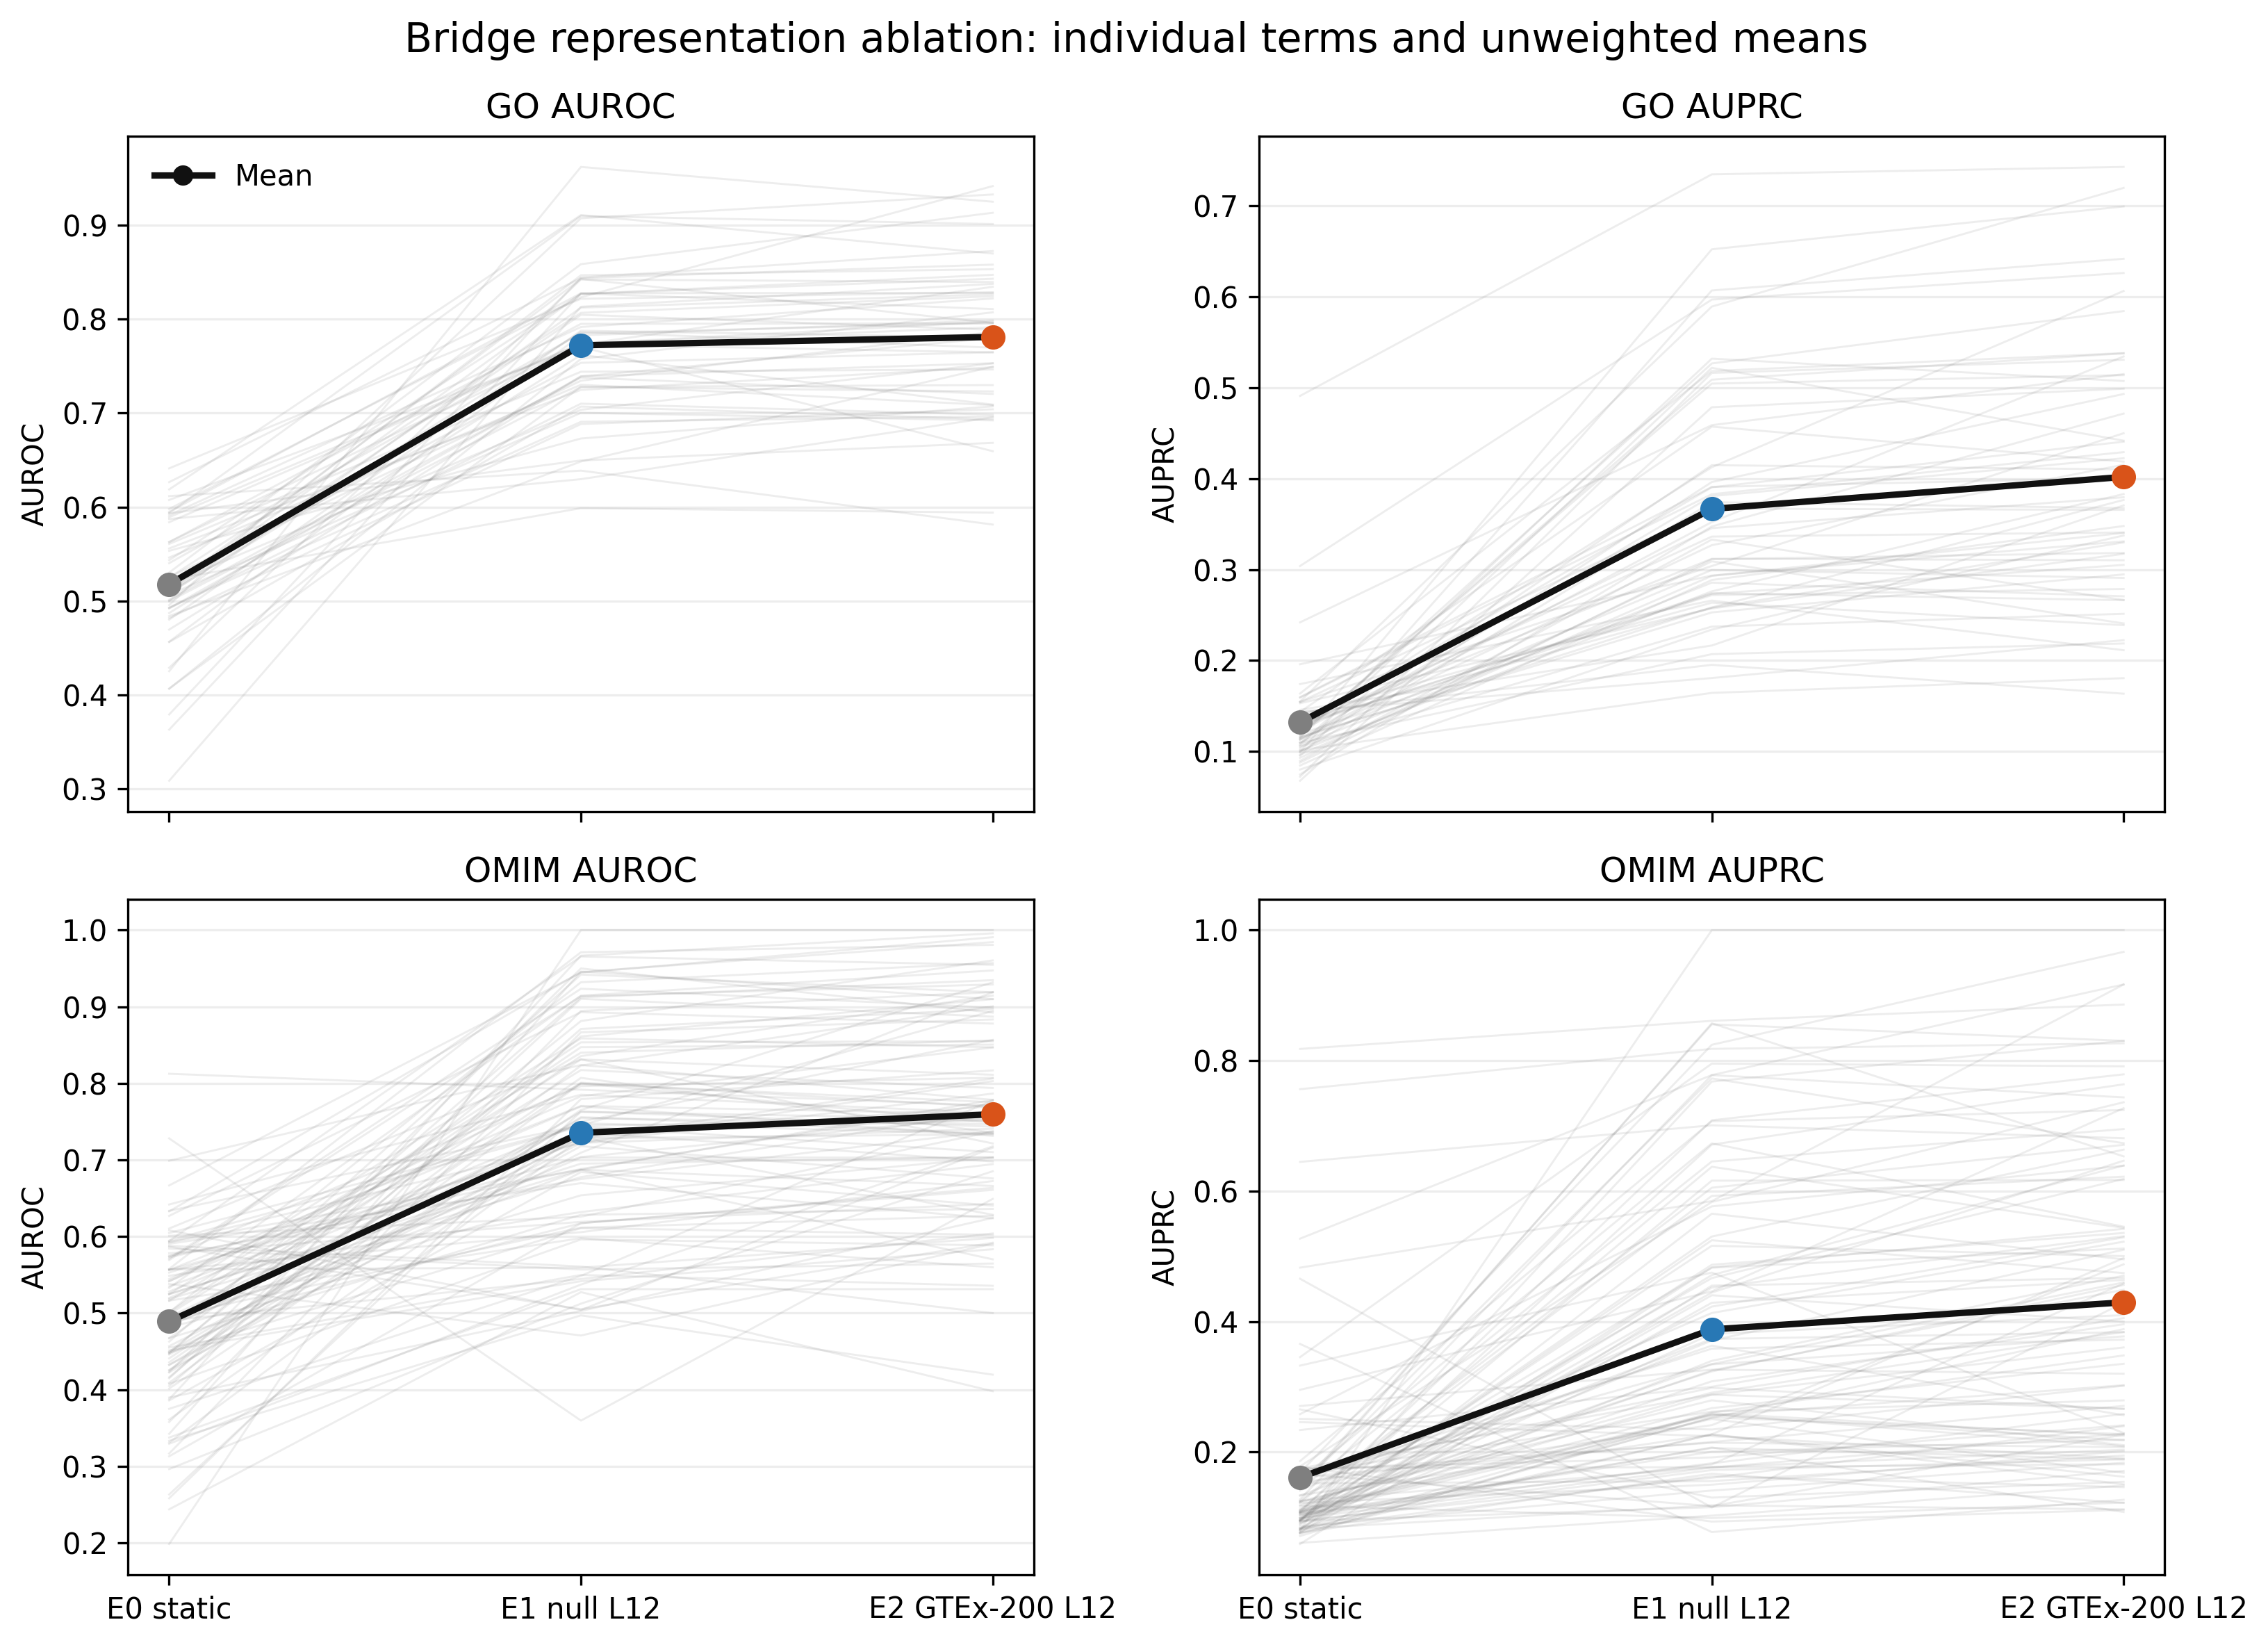

In [7]:
display(Image(filename=str(BENCH / "figures/final_representation_ablation.png")))

## Gene-pair prediction

,interaction_type,representation,joining_operation,outer_folds,AUROC_mean,AUROC_sd,AUPRC_mean,AUPRC_sd,Precision@10_mean,Precision@10_sd
0,NG,E0_static,concat,3,0.546,0.052,0.119,0.052,0.167,0.115
1,NG,E0_static,product,3,0.517,0.015,0.168,0.012,1.000,0.000
2,NG,E0_static,sum,3,0.569,0.039,0.172,0.037,0.800,0.265
3,NG,E1_null_L12,concat,3,0.566,0.040,0.129,0.026,0.167,0.058
4,NG,E1_null_L12,product,3,0.565,0.049,0.145,0.018,0.467,0.058
5,NG,E1_null_L12,sum,3,0.564,0.039,0.151,0.044,0.367,0.208
6,NG,E2_GTEx200_L12,concat,3,0.580,0.028,0.133,0.024,0.300,0.173
7,NG,E2_GTEx200_L12,product,3,0.575,0.072,0.160,0.039,0.600,0.265
8,NG,E2_GTEx200_L12,sum,3,0.578,0.033,0.143,0.018,0.300,0.200
9,SL,E0_static,concat,3,0.417,0.145,0.081,0.010,0.033,0.058


,Task,Representation,Pair_operation,AUROC,AUPRC,AUROC_sd,AUPRC_sd
0,Negative genetic,E2,concat,0.580,0.133,0.028,0.024
1,Synthetic lethal,E1,product,0.707,0.228,0.122,0.137
2,TF-target,E1,concat,0.670,0.186,0.040,0.014


,task,outer_fold,train_unique_genes,test_unique_genes,train_test_gene_overlap,n_train_pairs,n_test_pairs
0,NG,0,2473,1228,0,40181,10050
1,NG,1,2456,1245,0,40597,9972
2,NG,2,2473,1228,0,39894,10157
3,SL,0,1088,549,0,7700,2105
4,SL,1,1103,534,0,8399,1810
5,SL,2,1083,554,0,7712,2125
6,TF,0,4079,2050,0,36041,9360
7,TF,1,4081,2048,0,37022,8946
8,TF,2,4098,2031,0,36544,9084


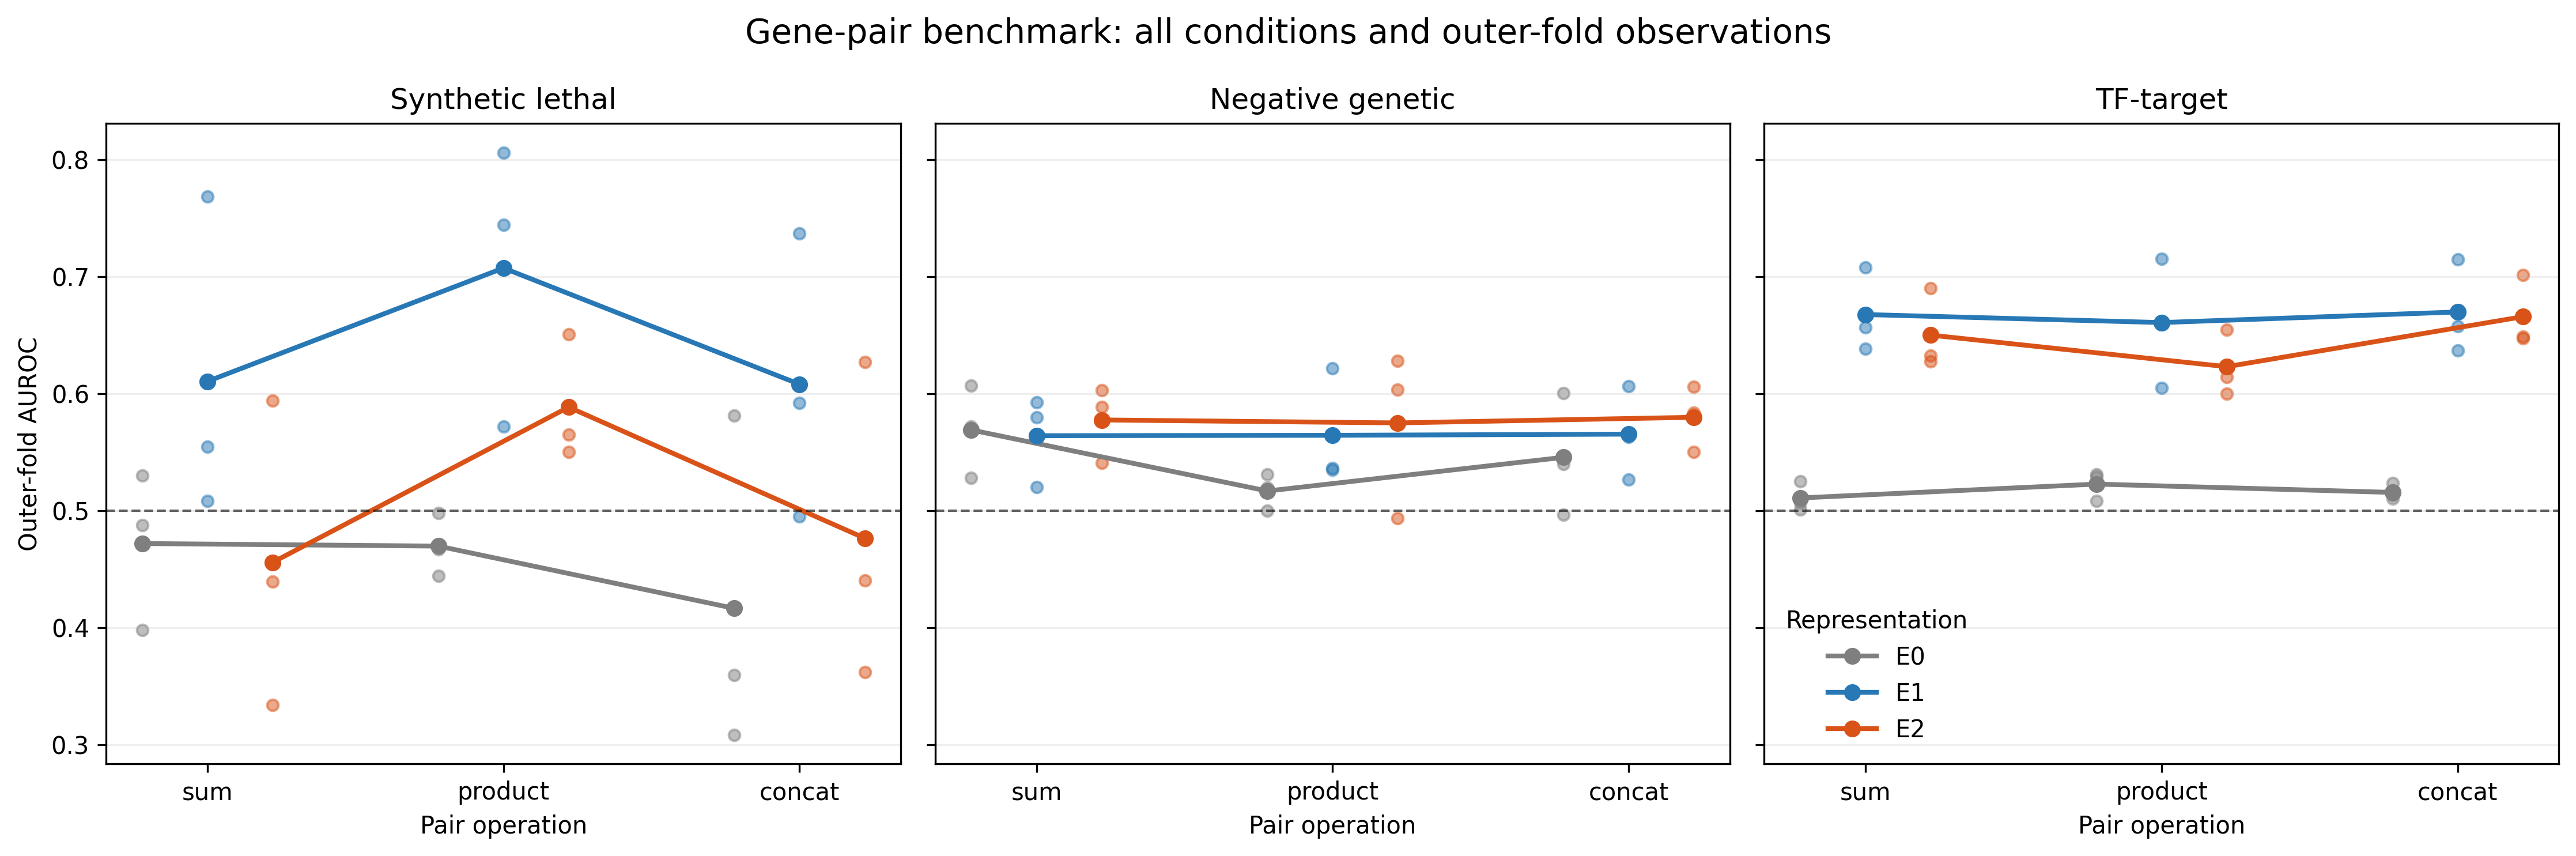

In [8]:
pair_path = RESULTS / "pair_representation_summary.csv"
if pair_path.exists():
    pair = pd.read_csv(pair_path)
    display(pair.round(3))
    display(pd.read_csv(RESULTS / "final_pair_best_conditions.csv").round(3))
    display(pd.read_csv(RESULTS / "final_pair_leakage_qc.csv"))
    display(Image(filename=str(BENCH / "figures/final_gene_pair_benchmark.png")))
else:
    print("Pair benchmark is still running; rerun this notebook after the checkpointed pipeline completes.")

## Biological-scale summary

,Biological_scale,Task,Representation,Pair_operation,AUROC,AUPRC,Aggregation
0,Single gene,GO,E0,—,0.5177,0.1321,unweighted mean across 56 terms
1,Single gene,GO,E1,—,0.7722,0.3668,unweighted mean across 56 terms
2,Single gene,GO,E2,—,0.7811,0.4019,unweighted mean across 56 terms
3,Single gene,OMIM,E0,—,0.4891,0.1609,unweighted mean across 103 terms
4,Single gene,OMIM,E1,—,0.7354,0.3879,unweighted mean across 103 terms
5,Single gene,OMIM,E2,—,0.7596,0.4294,unweighted mean across 103 terms
6,Gene pair,Negative genetic,E0,concat,0.5457,0.1189,mean across 3 outer folds
7,Gene pair,Negative genetic,E0,product,0.5169,0.1680,mean across 3 outer folds
8,Gene pair,Negative genetic,E0,sum,0.5691,0.1724,mean across 3 outer folds
9,Gene pair,Negative genetic,E1,concat,0.5655,0.1293,mean across 3 outer folds


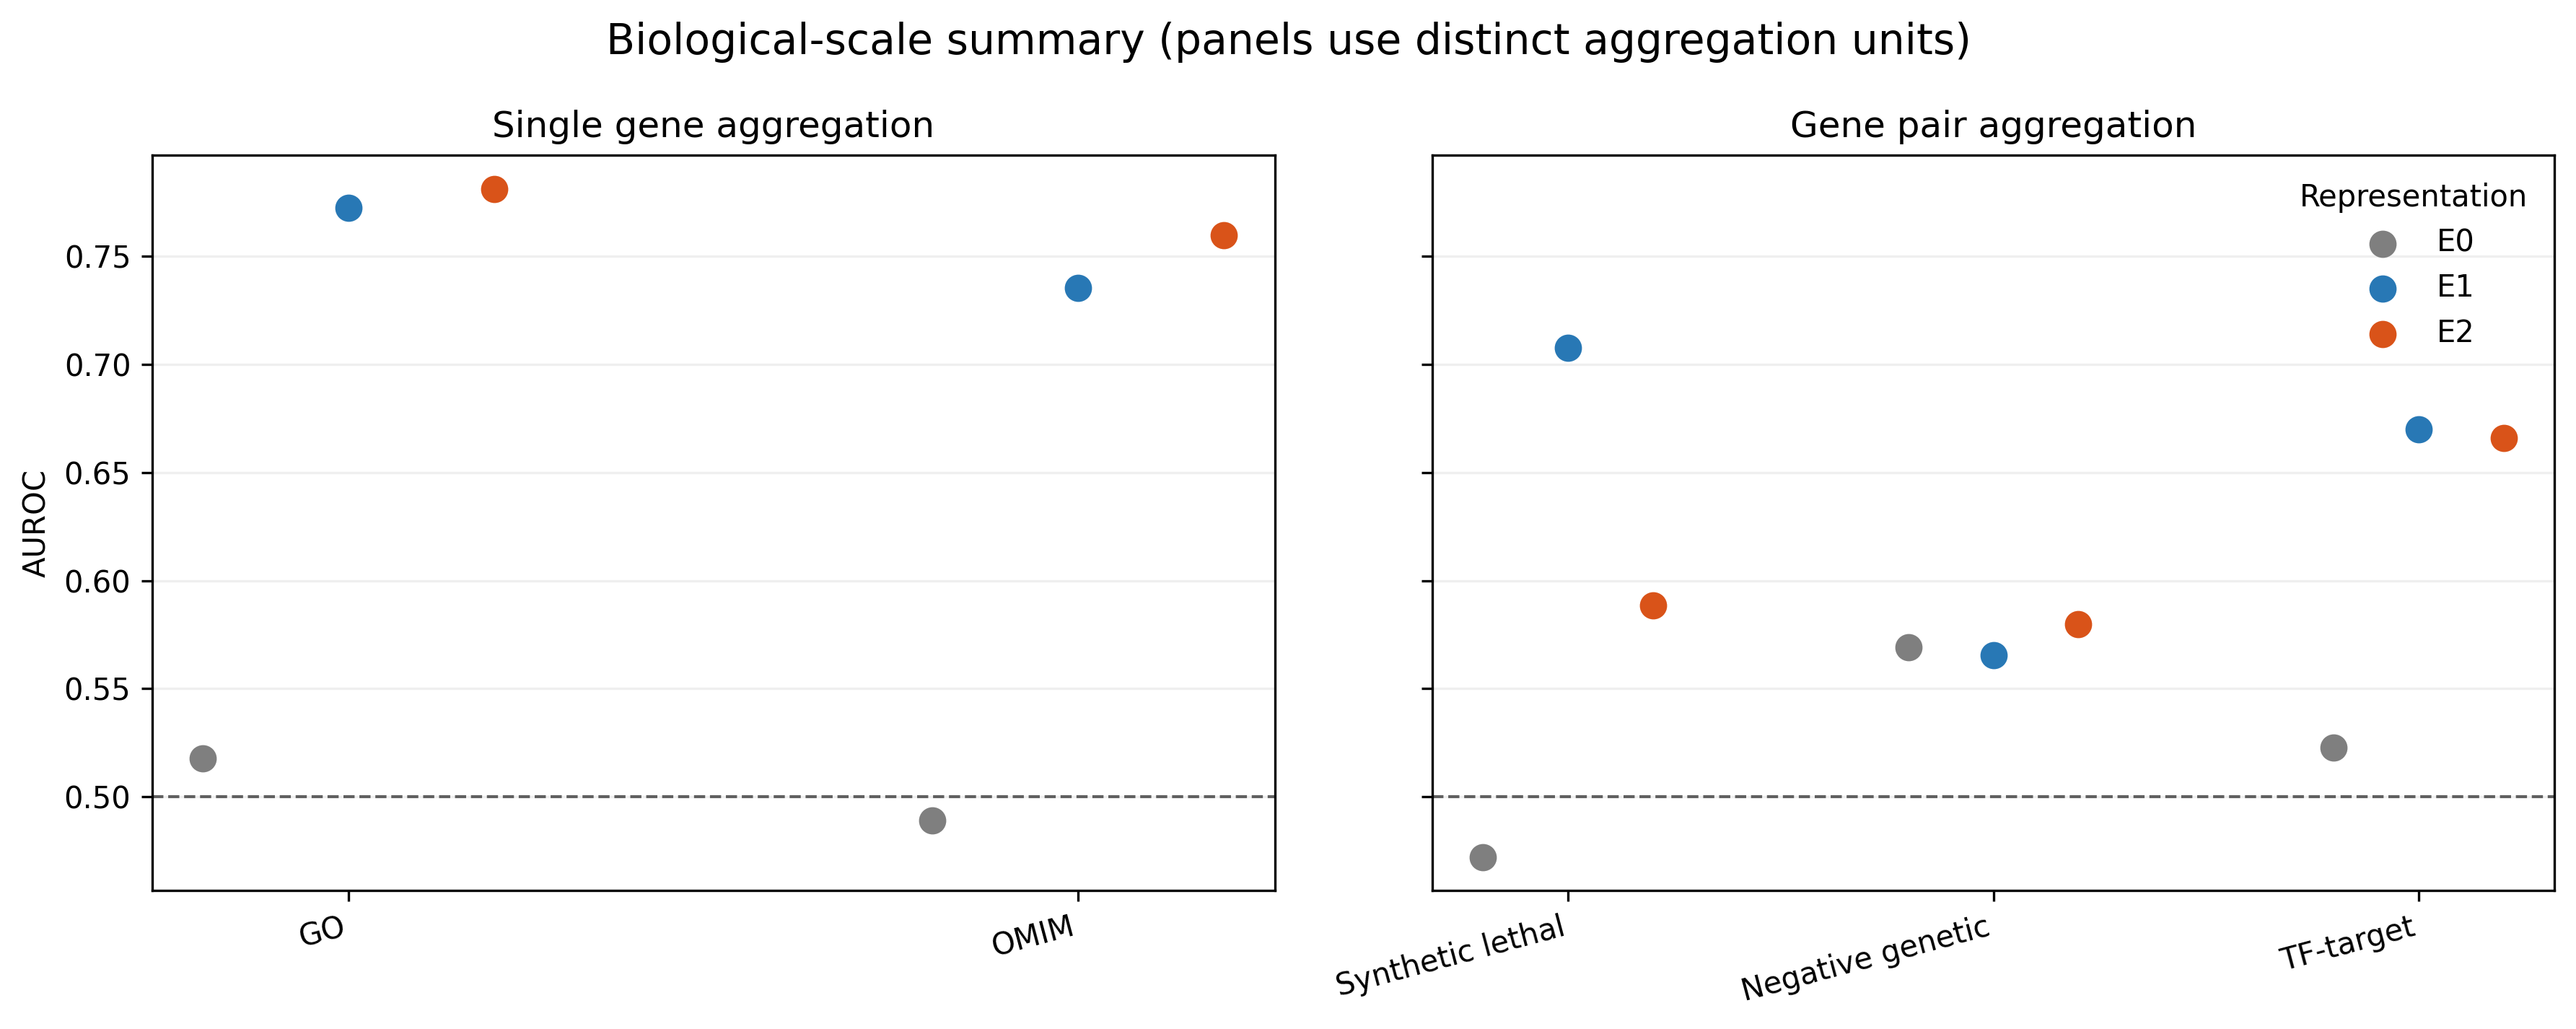

In [9]:
display(pd.read_csv(RESULTS / "final_benchmark_summary.csv").round(4))
display(Image(filename=str(BENCH / "figures/final_biological_scale_summary.png")))

## Limitations

The benchmark inherits Zhong et al.'s annotation sources, negative sampling, and split construction. Bridge pair outer folds are strictly gene-disjoint, with zero train/test gene overlap in every audited fold. GTEx-200 is a fixed bulk-tissue panel rather than a study-independent biological validation cohort. BulkFormer was evaluated only at the static single-gene level and uses its own available vocabulary; it was not evaluated contextually or on pair tasks. These probes establish decodability, not causal or mechanistic understanding, batch correction, or universal model superiority.